# Modelo gris simple

## Aplicado en nuevas observaciones (Diferentes a las utilizadas para la calibracion del sensor)

In [18]:
import pandas as pd
df = pd.read_excel("./../data/observaciones_10_11_2026.xlsx")
fecha = df["fecha"].dropna()
estacion_temp = df["estacion_temp"].dropna()
sensor_temp = df["sensor_temp"].dropna()

In [19]:
df.head()

,fecha,estacion_temp,estacion_hum,sensor_temp,sensor_hum,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48
0,2026-10-10 16:04:52,22.6,53.4,23.11,64.94,NaN,NaN,NaN,NaN,NaN,...,NaN,SUMMARY OUTPUT HUMEDAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-10 16:09:53,23.0,51.5,22.86,65.60,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-10 16:14:52,23.1,52.4,22.90,65.61,NaN,NaN,NaN,NaN,NaN,...,NaN,Regression Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-10 16:19:52,23.3,52.1,22.48,66.64,NaN,NaN,NaN,NaN,NaN,...,NaN,Multiple R,0.781783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-10 16:24:52,23.4,51.2,22.23,67.19,NaN,NaN,NaN,NaN,NaN,...,NaN,R Square,0.611185,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## PERIODO OBSEVADO
## Periodo observado: del 2026-10-10 16:04:52 al 2026-10-11 16:04:53

In [22]:
# Calcular el periodo observado
fecha_inicio = fecha.min()
fecha_fin = fecha.max()

print(f"Periodo observado: del {fecha_inicio.strftime('%Y-%m-%d %H:%M:%S')} al {fecha_fin.strftime('%Y-%m-%d %H:%M:%S')}")

Periodo observado: del 2026-10-10 16:04:52 al 2026-10-11 16:04:53


### Utiliza los ulitmos 4 valores

In [7]:
ultimos = estacion_temp.head(4)
# print(f"Valores analizados: \n{ultimos[0:5]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# ultimos = estacion_temp.tail(20)
# print(f"Valores analizados: \n{ultimos[0:20]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# UTILIZAR TODOS LOS DATOS
# ultimos = estacion_temp





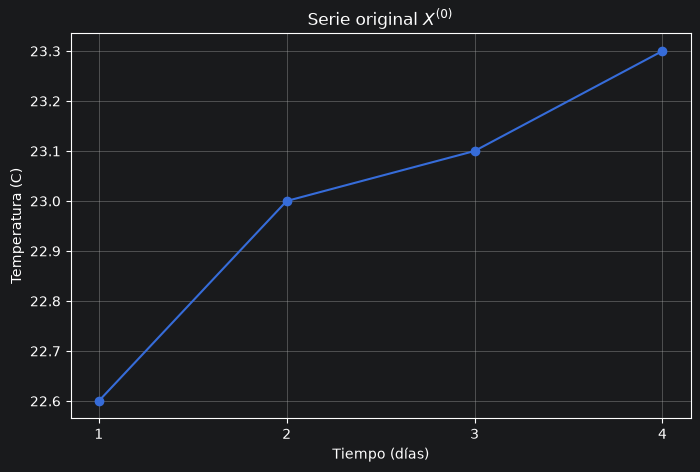

Serie original X^(0):
[22.6 23.  23.1 23.3]


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Serie original X^(0)
# ---------------------------------------------------------
X0 = ultimos.to_numpy(dtype=float)
#X0 = [820.0, 840.0, 835.0, 850.0, 890.0]


# Índice temporal
k = np.arange(1, len(X0) + 1)

# Graficación
plt.figure(figsize=(8, 5))
plt.plot(k, X0, marker='o')

plt.xlabel('Tiempo (días)')
plt.ylabel('Temperatura (C)')
plt.title(r'Serie original $X^{(0)}$')
plt.xticks(k)
plt.grid(True)

plt.show()

# Mostrar valores
print("Serie original X^(0):")
print(X0)

Serie original X^(0):
[22.6 23.  23.1 23.3]

Serie acumulada X^(1) obtenida mediante AGO:
[22.6 45.6 68.7 92. ]


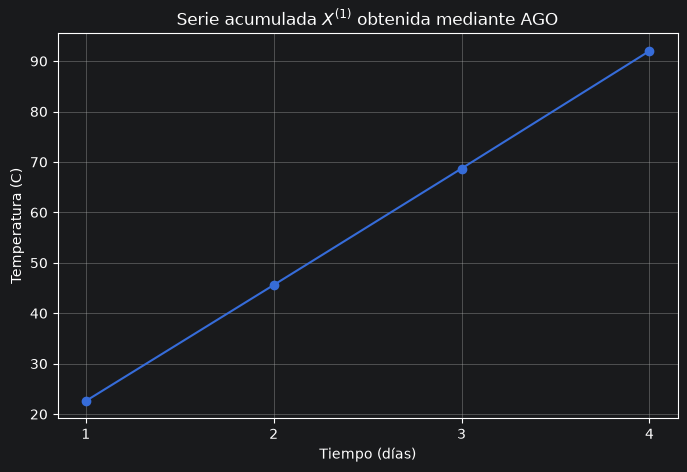

In [9]:
# ---------------------------------------------------------
# Operación AGO
#
# x^(1)(k) = sumatoria desde i=1 hasta k de x^(0)(i)
# ---------------------------------------------------------

X1 = np.cumsum(X0)

# Índices
k = np.arange(1, len(X1) + 1)

# Mostrar resultados
print("Serie original X^(0):")
print(X0)

print("\nSerie acumulada X^(1) obtenida mediante AGO:")
print(X1)

# ---------------------------------------------------------
# Graficación
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(k, X1, marker='o')

plt.xlabel('Tiempo (días)')
plt.ylabel('Temperatura (C)')
plt.title(r'Serie acumulada $X^{(1)}$ obtenida mediante AGO')
plt.xticks(k)
plt.grid(True)

plt.show()

In [10]:
# ---------------------------------------------------------
# Paso 2: Calcular la secuencia media generada Z^(1)
#
# z^(1)(k) = 0.5*x^(1)(k) + 0.5*x^(1)(k-1)
#
# k = 2, 3, ..., n
# ---------------------------------------------------------

Z1 = 0.5 * (X1[1:] + X1[:-1])

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

print("Serie original X^(0):")
print(X0)

print("\nSerie acumulada X^(1):")
print(X1)

print("\nSecuencia media generada Z^(1):")
print(Z1)

Serie original X^(0):
[22.6 23.  23.1 23.3]

Serie acumulada X^(1):
[22.6 45.6 68.7 92. ]

Secuencia media generada Z^(1):
[34.1  57.15 80.35]


In [11]:
# ---------------------------------------------------------
# Construcción de la matriz Y
# ---------------------------------------------------------

Y = X0[1:].reshape(-1, 1)
#Y = X0[1:]

# ---------------------------------------------------------
# Construcción de la matriz B
# ---------------------------------------------------------

B = np.column_stack((-Z1, np.ones(len(Z1))))

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

print("Matriz Y:")
print(Y)

print("\nMatriz B:")
print(B)

Matriz Y:
[[23. ]
 [23.1]
 [23.3]]

Matriz B:
[[-34.1    1.  ]
 [-57.15   1.  ]
 [-80.35   1.  ]]


In [12]:
# ---------------------------------------------------------
# Estimación de los parámetros a y b
#
# [a b]^T = (B^T B)^(-1) B^T Y
# ---------------------------------------------------------

parametros = np.linalg.inv(B.T @ B) @ B.T @ Y

a = parametros[0, 0]
b = parametros[1, 0]

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

np.set_printoptions(suppress=True, precision=6)

print("Matriz B:")
print(B)

print("\nMatriz Y:")
print(Y)

print("\nParámetros estimados:")
print("a =", a)
print("b =", b)

Matriz B:
[[-34.1    1.  ]
 [-57.15   1.  ]
 [-80.35   1.  ]]

Matriz Y:
[[23. ]
 [23.1]
 [23.3]]

Parámetros estimados:
a = -0.006488801208002382
b = 22.762173904235645


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Serie original X^(0)
# ---------------------------------------------------------
# Primer dato
x0_1 = X0[0]

# ---------------------------------------------------------
# Ecuación (12) del paper
#
# x_hat^(0)(k+1) =
# (x^(0)(1) - b/a) * exp(-a*k) * (1 - exp(a))
# ---------------------------------------------------------

k_modelo = np.arange(1, len(X0)+1)

X0_hat_restante = (
    (x0_1 - b/a)
    * np.exp(-a*k_modelo)
    * (1 - np.exp(a))
)

# El primer valor se conserva como condición inicial
X0_hat = np.concatenate(([x0_1], X0_hat_restante))

# Índice temporal para la gráfica
k = np.arange(1, len(X0) + 2)

# ---------------------------------------------------------
# Mostrar valores
# ---------------------------------------------------------
print("K:")
print(k)

print("X^(0) original:")
kb = np.concatenate(
    (X0, [None])
)
print(kb)

print("\nX_hat^(0) estimada:")
print(X0_hat)


K:
[1 2 3 4 5]
X^(0) original:
[22.6 23.0 23.1 23.3 None]

X_hat^(0) estimada:
[22.6      22.983307 23.132926 23.283519 23.435093]


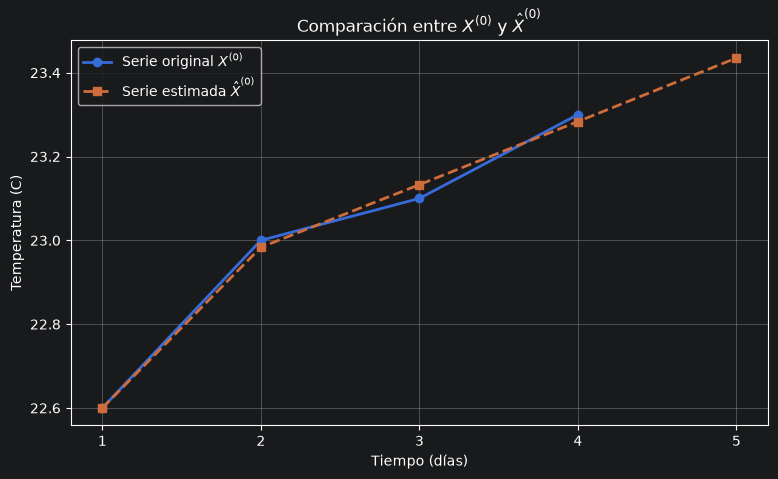

In [14]:
# ---------------------------------------------------------
# Graficación
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(k, kb,
         marker='o',
         linewidth=2,
         label=r'Serie original $X^{(0)}$')

plt.plot(k, X0_hat,
         marker='s',
         linestyle='--',
         linewidth=2,
         label=r'Serie estimada $\hat{X}^{(0)}$')

plt.xlabel('Tiempo (días)')
plt.ylabel('Temperatura (C)')
plt.title(r'Comparación entre $X^{(0)}$ y $\hat{X}^{(0)}$')

plt.xticks(k)
plt.grid(True)
plt.legend()

plt.show()

In [15]:
import numpy as np
x0_1 = X0[0]

k = np.arange(1, len(X0)+2)

X0_hat_restante = (
    (x0_1 - b/a)
    * np.exp(-a*k)
    * (1 - np.exp(a))
)
X0_hat_restante

array([22.983307, 23.132926, 23.283519, 23.435093, 23.587653])

In [16]:
import numpy as np

x0_1 = X0[0]

# ---------------------------------------------------------
# Ecuación (12): valores estimados
# ---------------------------------------------------------

k = np.arange(1, len(X0))

X0_hat_restante = (
    (x0_1 - b/a)
    * np.exp(-a*k)
    * (1 - np.exp(a))
)

# Condición inicial
X0_hat = np.concatenate(([x0_1], X0_hat_restante))

# ---------------------------------------------------------
# ECUACIÓN (37)
# Error
#
# error(k) = x^(0)(k) - x_hat^(0)(k)
# ---------------------------------------------------------

error = X0 - X0_hat

# ---------------------------------------------------------
# ECUACIÓN (38)
# Relative Percentage Error
#
# RPE(k) = |error(k)| / x^(0)(k) * 100
# ---------------------------------------------------------

RPE = np.abs(error) / X0 * 100

# ---------------------------------------------------------
# ECUACIÓN (39)
# Average Relative Percentage Error
#
# Se excluye el primer dato porque es la condición inicial
# ---------------------------------------------------------

ARPE = np.mean(RPE[1:])

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

print("k\tX0\t\tX0_hat\t\tError\t\tRPE (%)")

for i in range(len(X0)):
    print(
        f"{i+1}\t"
        f"{X0[i]:.4f}\t"
        f"{X0_hat[i]:.4f}\t"
        f"{error[i]:.4f}\t"
        f"{RPE[i]:.4f}"
    )

print("\nARPE = {:.4f} %".format(ARPE))

k	X0		X0_hat		Error		RPE (%)
1	22.6000	22.6000	0.0000	0.0000
2	23.0000	22.9833	0.0167	0.0726
3	23.1000	23.1329	-0.0329	0.1425
4	23.3000	23.2835	0.0165	0.0707

ARPE = 0.0953 %


Error:
[ 0.        0.016693 -0.032926  0.016481]

RPE (%):
[0.       0.072577 0.142538 0.070733]

ARPE = 0.0953 %


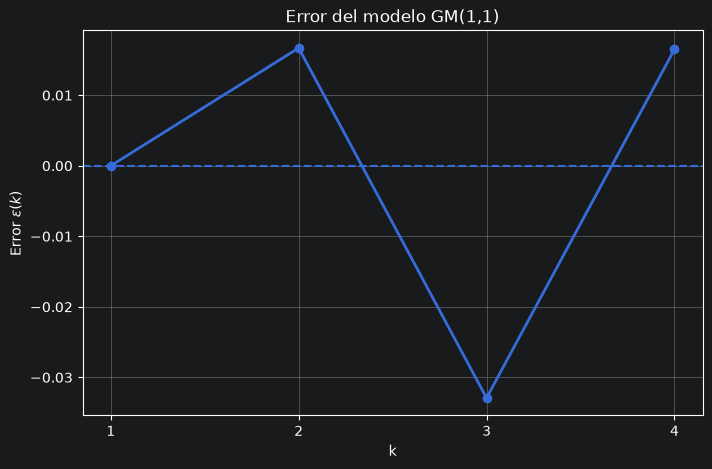

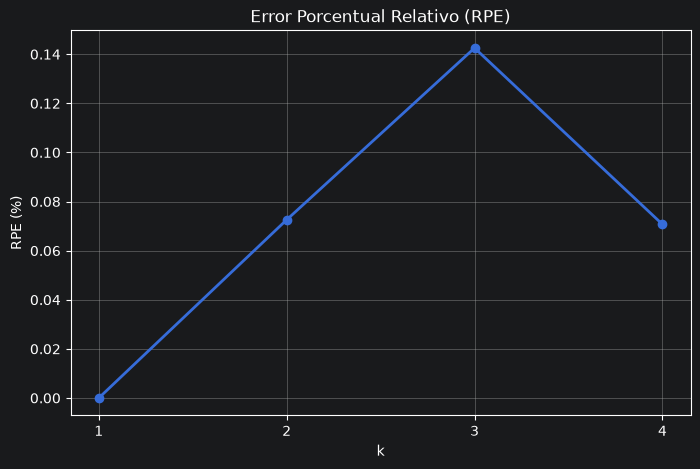

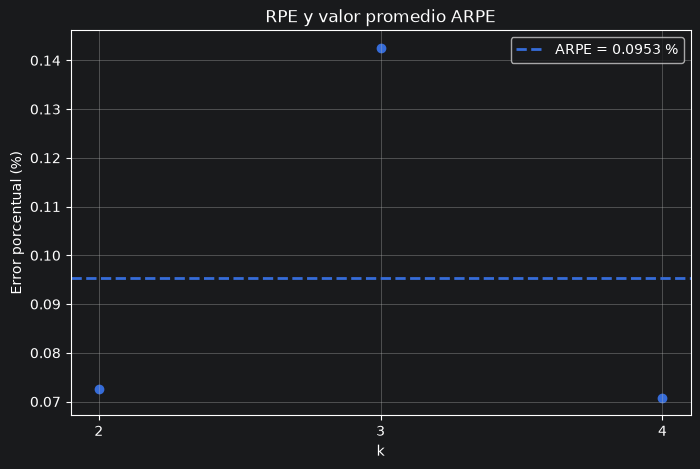

In [17]:
import numpy as np
import matplotlib.pyplot as plt

x0_1 = X0[0]

# =========================================================
# ECUACIÓN (12): SERIE ESTIMADA
# =========================================================

k_modelo = np.arange(1, len(X0))

X0_hat_restante = (
    (x0_1 - b/a)
    * np.exp(-a*k_modelo)
    * (1 - np.exp(a))
)

# Primer valor = condición inicial
X0_hat = np.concatenate(([x0_1], X0_hat_restante))

# Índice temporal
k = np.arange(1, len(X0) + 1)

# =========================================================
# ECUACIÓN (37): ERROR
#
# error(k) = X0(k) - X0_hat(k)
# =========================================================

error = X0 - X0_hat

# =========================================================
# ECUACIÓN (38): RPE
#
# RPE(k) = |error(k)| / X0(k) * 100
# =========================================================

RPE = np.abs(error) / X0 * 100

# =========================================================
# ECUACIÓN (39): ARPE
#
# Se excluye k = 1 porque es la condición inicial
# =========================================================

ARPE = np.mean(RPE[1:])

# =========================================================
# MOSTRAR RESULTADOS
# =========================================================

print("Error:")
print(error)

print("\nRPE (%):")
print(RPE)

print("\nARPE = {:.4f} %".format(ARPE))


# =========================================================
# GRÁFICA 1: ERROR
# =========================================================

plt.figure(figsize=(8, 5))

plt.plot(k, error, marker='o', linewidth=2)
plt.axhline(y=0, linestyle='--')

plt.xlabel('k')
plt.ylabel(r'Error $\varepsilon(k)$')
plt.title(r'Error del modelo GM(1,1)')

plt.xticks(k)
plt.grid(True)

plt.show()


# =========================================================
# GRÁFICA 2: RPE
# =========================================================

plt.figure(figsize=(8, 5))

plt.plot(k, RPE, marker='o', linewidth=2)

plt.xlabel('k')
plt.ylabel('RPE (%)')
plt.title('Error Porcentual Relativo (RPE)')

plt.xticks(k)
plt.grid(True)

plt.show()


# =========================================================
# GRÁFICA 3: ARPE
# =========================================================

plt.figure(figsize=(8, 5))

# El ARPE es un único valor, por lo que se representa
# como una línea horizontal
plt.axhline(
    y=ARPE,
    linestyle='--',
    linewidth=2,
    label=f'ARPE = {ARPE:.4f} %'
)

plt.scatter(k[1:], RPE[1:])

plt.xlabel('k')
plt.ylabel('Error porcentual (%)')
plt.title('RPE y valor promedio ARPE')

plt.xticks(k[1:])
plt.grid(True)
plt.legend()

plt.show()